
# Analisis Prediksi Jumlah Pembelian Konsumen E-Commerce Menggunakan Regresi Linear Berganda

## Deskripsi
Penelitian ini bertujuan untuk memprediksi jumlah pembelian konsumen e-commerce berdasarkan karakteristik dan perilaku pelanggan menggunakan metode Regresi Linear Berganda.

Dataset yang digunakan adalah Ecommerce Consumer Behavior Analysis Data dengan 1.000 baris data dan 28 atribut.

*Nama:* M.ZULHI SATRIO N 05TPLP018  
*Mata Kuliah:* Machine Learning

## Tujuan Penelitian
1. Mengetahui faktor yang berhubungan dengan jumlah pembelian konsumen.
2. Membangun model prediksi menggunakan Regresi Linear Berganda.
3. Mengevaluasi performa model menggunakan MAE, RMSE, dan R².

## Variabel Penelitian
- Variabel target (Y): Purchase_Amount
- Variabel prediktor (X): Age, Frequency_of_Purchase, Brand_Loyalty, Product_Rating, Time_Spent_on_Product_Research(hours), Return_Rate, Customer_Satisfaction, dan Time_to_Decision.

## Metode
Metode yang digunakan adalah Regresi Linear Berganda dengan pembagian data latih dan data uji.


## 1. Import Library

Tahap ini digunakan untuk memanggil library Python yang dibutuhkan dalam pengolahan data, pembuatan grafik, pembagian dataset, pemodelan regresi, dan evaluasi hasil prediksi.

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score



## 2. Membaca Dataset

Pada tahap ini, program membaca file CSV menggunakan pandas. Dataset disimpan dalam variabel `df` agar dapat digunakan pada proses pemeriksaan dan analisis data berikutnya.

Pastikan file CSV berada di folder yang sama dengan notebook.

In [4]:

df = pd.read_csv("dataset/Ecommerce_Consumer_Behavior_Analysis_Data.csv")

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (1000, 28)


,Customer_ID,Age,Gender,Income_Level,Marital_Status,Education_Level,Occupation,Location,Purchase_Category,Purchase_Amount,...,Customer_Satisfaction,Engagement_with_Ads,Device_Used_for_Shopping,Payment_Method,Time_of_Purchase,Discount_Used,Customer_Loyalty_Program_Member,Purchase_Intent,Shipping_Preference,Time_to_Decision
0,37-611-6911,22,Female,Middle,Married,Bachelor's,Middle,Évry,Gardening & Outdoors,$333.80,...,7,NaN,Tablet,Credit Card,3/1/2024,True,False,Need-based,No Preference,2
1,29-392-9296,49,Male,High,Married,High School,High,Huocheng,Food & Beverages,$222.22,...,5,High,Tablet,PayPal,4/16/2024,True,False,Wants-based,Standard,6
2,84-649-5117,24,Female,Middle,Single,Master's,High,Huzhen,Office Supplies,$426.22,...,7,Low,Smartphone,Debit Card,3/15/2024,True,True,Impulsive,No Preference,3
3,48-980-6078,29,Female,Middle,Single,Master's,Middle,Wiwilí,Home Appliances,$101.31,...,1,NaN,Smartphone,Other,10/4/2024,True,True,Need-based,Express,10
4,91-170-9072,33,Female,Middle,Widowed,High School,Middle,Nara,Furniture,$211.70,...,10,NaN,Smartphone,Debit Card,1/30/2024,False,False,Wants-based,No Preference,4



## 3. Pemeriksaan Awal Dataset

Tahap ini digunakan untuk melihat nama kolom, tipe data, jumlah data kosong, dan informasi umum dataset. Pemeriksaan ini penting untuk mengetahui kondisi data sebelum dilakukan pemodelan.

In [5]:

print("Nama kolom:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()

print("\nJumlah data kosong:")
display(df.isnull().sum())

Nama kolom:
['Customer_ID', 'Age', 'Gender', 'Income_Level', 'Marital_Status', 'Education_Level', 'Occupation', 'Location', 'Purchase_Category', 'Purchase_Amount', 'Frequency_of_Purchase', 'Purchase_Channel', 'Brand_Loyalty', 'Product_Rating', 'Time_Spent_on_Product_Research(hours)', 'Social_Media_Influence', 'Discount_Sensitivity', 'Return_Rate', 'Customer_Satisfaction', 'Engagement_with_Ads', 'Device_Used_for_Shopping', 'Payment_Method', 'Time_of_Purchase', 'Discount_Used', 'Customer_Loyalty_Program_Member', 'Purchase_Intent', 'Shipping_Preference', 'Time_to_Decision']

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Customer_ID                            1000 non-null   str    
 1   Age                                    1000 non-null   int64  
 2   Gender                        

Customer_ID                                0
Age                                        0
Gender                                     0
Income_Level                               0
Marital_Status                             0
Education_Level                            0
Occupation                                 0
Location                                   0
Purchase_Category                          0
Purchase_Amount                            0
Frequency_of_Purchase                      0
Purchase_Channel                           0
Brand_Loyalty                              0
Product_Rating                             0
Time_Spent_on_Product_Research(hours)      0
Social_Media_Influence                   247
Discount_Sensitivity                       0
Return_Rate                                0
Customer_Satisfaction                      0
Engagement_with_Ads                      256
Device_Used_for_Shopping                   0
Payment_Method                             0
Time_of_Pu


## 4. Pembersihan Data

Kolom `Purchase_Amount` berisi nilai pembelian dengan simbol dolar sehingga perlu dikonversi menjadi tipe numerik. Setelah itu, data yang tidak memiliki nilai target akan dihapus karena tidak dapat digunakan sebagai jawaban yang ingin diprediksi.

Data kosong pada variabel prediktor akan ditangani menggunakan median melalui pipeline model.

In [6]:

# Mengubah Purchase_Amount menjadi angka
df["Purchase_Amount"] = pd.to_numeric(
    df["Purchase_Amount"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# Menghapus baris tanpa nilai target
df = df.dropna(subset=["Purchase_Amount"]).copy()

print("Ukuran data setelah pembersihan:", df.shape)
print("\nTipe data Purchase_Amount:")
print(df["Purchase_Amount"].dtype)

display(df[["Purchase_Amount"]].head())

Ukuran data setelah pembersihan: (1000, 28)

Tipe data Purchase_Amount:
float64


,Purchase_Amount
0,333.80
1,222.22
2,426.22
3,101.31
4,211.70



## 5. Analisis Deskriptif

Analisis deskriptif digunakan untuk mengetahui gambaran umum data, seperti nilai rata-rata, standar deviasi, nilai minimum, dan maksimum. Informasi ini membantu memahami karakteristik variabel yang digunakan dalam penelitian.

In [7]:

kolom_analisis = [
    "Age",
    "Frequency_of_Purchase",
    "Brand_Loyalty",
    "Product_Rating",
    "Time_Spent_on_Product_Research(hours)",
    "Return_Rate",
    "Customer_Satisfaction",
    "Time_to_Decision",
    "Purchase_Amount"
]

display(df[kolom_analisis].describe().round(2))

,Age,Frequency_of_Purchase,Brand_Loyalty,Product_Rating,Time_Spent_on_Product_Research(hours),Return_Rate,Customer_Satisfaction,Time_to_Decision,Purchase_Amount
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,34.30,6.94,3.03,3.03,1.01,0.95,5.40,7.55,275.06
std,9.35,3.15,1.42,1.44,0.79,0.81,2.87,4.04,131.53
min,18.00,2.00,1.00,1.00,0.00,0.00,1.00,1.00,50.71
25%,26.00,4.00,2.00,2.00,0.00,0.00,3.00,4.00,162.24
50%,34.50,7.00,3.00,3.00,1.00,1.00,5.00,8.00,276.16
75%,42.00,10.00,4.00,4.00,2.00,2.00,8.00,11.00,388.98
max,50.00,12.00,5.00,5.00,2.00,2.00,10.00,14.00,498.33



## 6. Visualisasi Data

Visualisasi digunakan untuk melihat distribusi jumlah pembelian dan hubungan awal antara frekuensi pembelian dengan jumlah pembelian konsumen. Grafik ini merupakan bagian dari eksplorasi data, bukan bukti bahwa suatu variabel menyebabkan perubahan variabel lainnya.

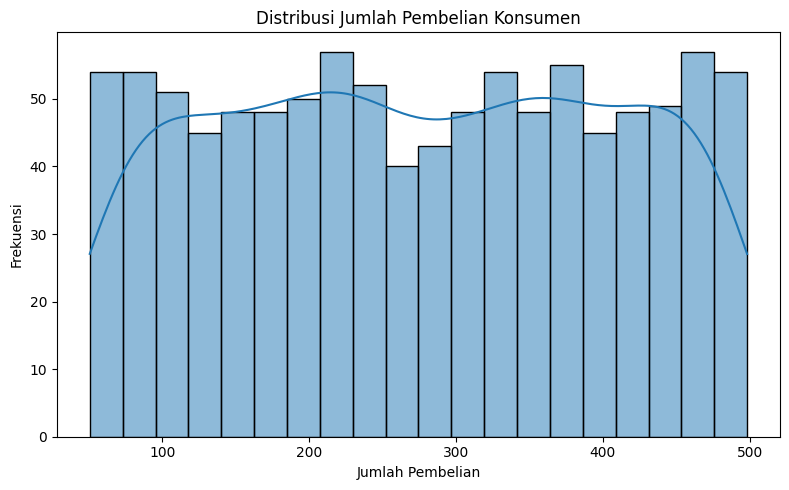

In [8]:

plt.figure(figsize=(8, 5))
sns.histplot(df["Purchase_Amount"], bins=20, kde=True)

plt.title("Distribusi Jumlah Pembelian Konsumen")
plt.xlabel("Jumlah Pembelian")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

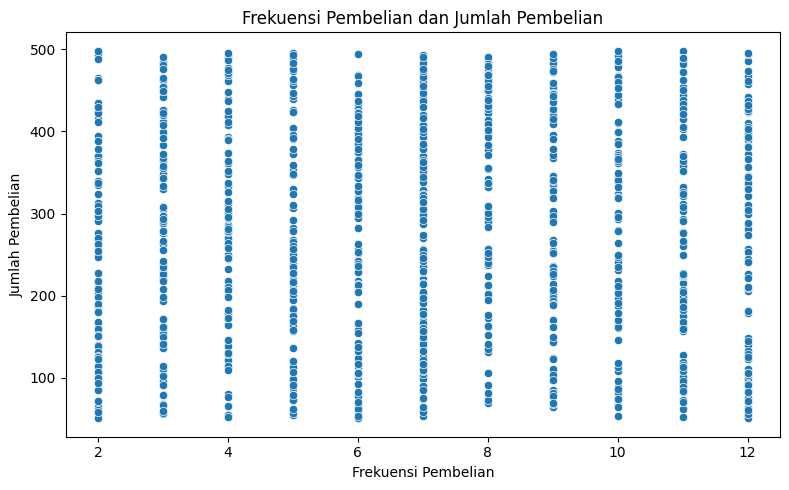

In [9]:

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Frequency_of_Purchase",
    y="Purchase_Amount"
)

plt.title("Frekuensi Pembelian dan Jumlah Pembelian")
plt.xlabel("Frekuensi Pembelian")
plt.ylabel("Jumlah Pembelian")
plt.tight_layout()
plt.show()


## 7. Menentukan Variabel Penelitian

Variabel target (Y) adalah `Purchase_Amount`, yaitu jumlah pembelian konsumen yang ingin diprediksi.

Variabel prediktor (X) terdiri dari usia, frekuensi pembelian, loyalitas merek, rating produk, waktu penelitian produk, tingkat pengembalian, kepuasan pelanggan, dan waktu pengambilan keputusan.

Pemilihan variabel numerik dilakukan agar pemodelan awal lebih sederhana dan mudah dipahami.

In [10]:

fitur = [
    "Age",
    "Frequency_of_Purchase",
    "Brand_Loyalty",
    "Product_Rating",
    "Time_Spent_on_Product_Research(hours)",
    "Return_Rate",
    "Customer_Satisfaction",
    "Time_to_Decision"
]

target = "Purchase_Amount"

X = df[fitur]
y = df[target]

print("Jumlah fitur:", len(fitur))
print("Jumlah data:", len(X))

display(X.head())
display(y.head())

Jumlah fitur: 8
Jumlah data: 1000


,Age,Frequency_of_Purchase,Brand_Loyalty,Product_Rating,Time_Spent_on_Product_Research(hours),Return_Rate,Customer_Satisfaction,Time_to_Decision
0,22,4,5,5,2.0,1,7,2
1,49,11,3,1,2.0,1,5,6
2,24,2,5,5,0.3,1,7,3
3,29,6,3,1,1.0,0,1,10
4,33,6,3,4,0.0,2,10,4


0    333.80
1    222.22
2    426.22
3    101.31
4    211.70
Name: Purchase_Amount, dtype: float64


## 8. Pembagian Dataset

Dataset dibagi menjadi 80% data latih dan 20% data uji. Data latih digunakan untuk membangun model, sedangkan data uji digunakan untuk mengevaluasi kemampuan model dalam memprediksi data yang tidak digunakan saat pelatihan.

Random state ditetapkan agar pembagian data dapat direproduksi.

In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 800
Jumlah data uji: 200



## 9. Pembuatan Model Regresi Linear Berganda

Model Regresi Linear Berganda digunakan untuk mempelajari hubungan linear antara beberapa variabel prediktor dan jumlah pembelian.

Pipeline digunakan agar nilai kosong pada fitur diisi menggunakan median berdasarkan data latih, kemudian model dilatih. Pendekatan ini membantu menghindari kebocoran informasi dari data uji ke data latih.

In [12]:

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regresi", LinearRegression())
])

model.fit(X_train, y_train)

print("Model regresi berhasil dilatih.")

Model regresi berhasil dilatih.



## 10. Prediksi Data Uji

Setelah proses pelatihan selesai, model digunakan untuk memprediksi jumlah pembelian pada data uji. Hasil prediksi kemudian dibandingkan dengan nilai pembelian sebenarnya untuk mengetahui tingkat kesalahan model.

In [13]:

y_pred = model.predict(X_test)

hasil_prediksi = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": y_pred
})

hasil_prediksi["Selisih"] = (
    hasil_prediksi["Aktual"] - hasil_prediksi["Prediksi"]
)

display(hasil_prediksi.head(10))

,Aktual,Prediksi,Selisih
0,444.05,257.727008,186.322992
1,178.21,284.906076,-106.696076
2,85.52,295.852996,-210.332996
3,55.73,267.159285,-211.429285
4,442.15,279.989297,162.160703
5,195.83,287.213658,-91.383658
6,83.33,288.233857,-204.903857
7,438.26,276.567390,161.692610
8,54.74,296.538059,-241.798059
9,164.79,265.474223,-100.684223



## 11. Evaluasi Model

Evaluasi dilakukan menggunakan tiga metrik, yaitu MAE, RMSE, dan R².

- MAE mengukur rata-rata nilai absolut kesalahan prediksi.
- RMSE mengukur kesalahan prediksi dengan memberikan penalti lebih besar pada kesalahan yang besar.
- R² mengukur proporsi variasi target yang dapat dijelaskan oleh model pada data evaluasi.

MAE dan RMSE yang lebih rendah umumnya lebih baik. Nilai R² yang lebih tinggi menunjukkan kecocokan yang lebih baik, tetapi tidak selalu menjamin kemampuan prediksi pada data baru.

In [14]:

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Hasil Evaluasi Model")
print("--------------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Hasil Evaluasi Model
--------------------
MAE  : 114.98
RMSE : 132.36
R²   : -0.0061



## 12. Visualisasi Hasil Prediksi

Grafik ini membandingkan jumlah pembelian aktual dengan hasil prediksi model. Titik yang mendekati garis diagonal menunjukkan prediksi yang lebih dekat dengan nilai aktual.

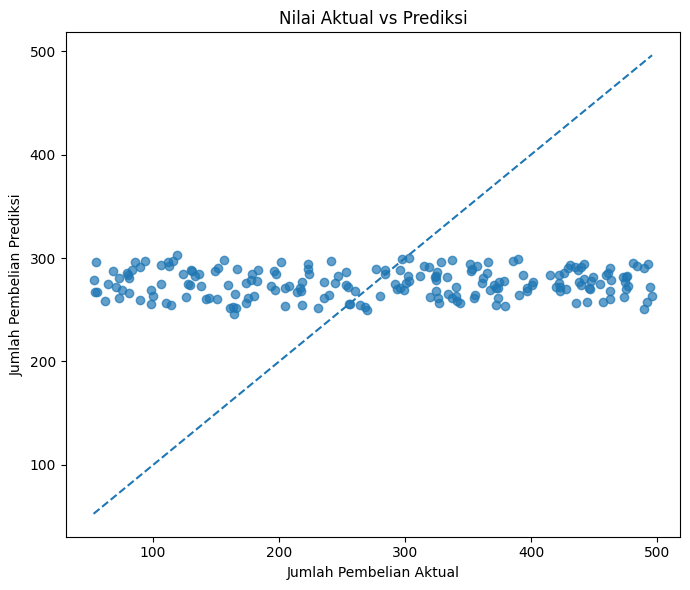

In [15]:

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

batas_min = min(y_test.min(), y_pred.min())
batas_max = max(y_test.max(), y_pred.max())

plt.plot(
    [batas_min, batas_max],
    [batas_min, batas_max],
    linestyle="--"
)

plt.title("Nilai Aktual vs Prediksi")
plt.xlabel("Jumlah Pembelian Aktual")
plt.ylabel("Jumlah Pembelian Prediksi")
plt.tight_layout()
plt.show()


## 13. Analisis Koefisien Regresi

Koefisien regresi menunjukkan arah hubungan linear setiap fitur dengan target ketika fitur lainnya dianggap tetap. Koefisien positif menunjukkan hubungan searah dalam model, sedangkan koefisien negatif menunjukkan hubungan berlawanan arah.

Koefisien tidak boleh langsung dianggap sebagai bukti sebab-akibat.

In [16]:

regresi = model.named_steps["regresi"]

koefisien = pd.DataFrame({
    "Variabel": fitur,
    "Koefisien": regresi.coef_
})

display(
    koefisien.sort_values(
        by="Koefisien",
        ascending=False
    ).round(4)
)

print("Intercept:", round(regresi.intercept_, 4))

,Variabel,Koefisien
3,Product_Rating,1.2732
7,Time_to_Decision,0.2597
1,Frequency_of_Purchase,-0.0517
0,Age,-0.2134
6,Customer_Satisfaction,-0.8224
4,Time_Spent_on_Product_Research(hours),-1.2533
5,Return_Rate,-4.4212
2,Brand_Loyalty,-8.3715


Intercept: 310.9731



## 14. Kesimpulan

Berdasarkan hasil pemodelan, evaluasi MAE, RMSE, dan R² digunakan untuk menilai kemampuan Regresi Linear Berganda dalam memprediksi jumlah pembelian konsumen e-commerce.

Kesimpulan akhir harus disesuaikan dengan nilai evaluasi yang diperoleh dari notebook. Apabila kesalahan prediksi masih besar atau nilai R² rendah, model perlu ditinjau kembali melalui pemeriksaan data, pemilihan fitur, dan perbandingan dengan model lain.

Hasil penelitian menunjukkan kemampuan prediksi pada data yang diuji dan tidak secara otomatis membuktikan hubungan sebab-akibat.